# Logictic Regression - Banking Term Deposits

**Summary:** predicting whether a bank client subscribes to a term deposit from 41,188 direct-marketing call records (21 features, [UCI Bank Marketing dataset](https://archive.ics.uci.edu/dataset/222/bank+marketing)). After encoding, RFECV feature selection and a tuned logistic regression, the model reaches 86% accuracy — but the real gain comes from rebalancing with `class_weight='balanced'`, which raises recall on the "will subscribe" class from 43% to 91%, a much better trade-off for a marketing campaign that would rather over-call than miss a buyer.

The goal of this exercise is to practice:
* data exploration
* data processing
* data modeling with a logistic regression model
* model performance evaluation

## Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## Big picture

The data is related to direct marketing campaigns (phone calls) of a Portuguese banking institution. The classification goal is to predict if the client will subscribe (1/0) a term deposit. This dataset provides the customer information. It includes 41188 records and 21 fields.

* What is your ML task? Describe it precisely.

In [3]:
# Load the dataset
df = pd.read_csv('bank.csv', sep=';')

## Get the data

* Get the data and quickly check your df (shape, columns).

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

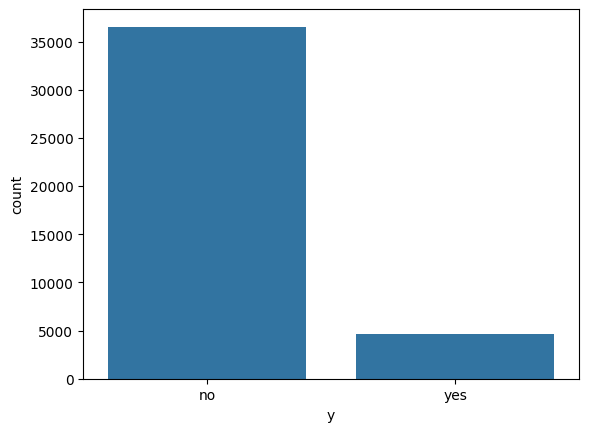

In [5]:

# Check the first few rows
df.head()

# Check dataset info (types and missing values)
df.info()

# Statistical summary of numerical columns
df.describe()

# Check the distribution of the target variable 'y'
sns.countplot(x='y', data=df)
plt.show()

## Data exploration & processing

### Variables discovery

1 - "age" (numeric)

2 - "job" : type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')

3 - "marital" : marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)

4 - "education" (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')

5 - "default": has credit in default? (categorical: 'no','yes','unknown')

6 - "housing": has housing loan? (categorical: 'no','yes','unknown')

7 - "loan": has personal loan? (categorical: 'no','yes','unknown')

8 - "contact": contact communication type (categorical: 'cellular','telephone')

9 - "month": last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')

10 - "day_of_week": last contact day of the week (categorical: 'mon','tue','wed','thu','fri')

11 - "duration": last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.

12 - "campaign": number of contacts performed during this campaign and for this client (numeric, includes last contact)

13 - "pdays": number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)

14 - "previous": number of contacts performed before this campaign and for this client (numeric)

15 - "poutcome": outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')

16 - "emp.var.rate": employment variation rate - (numeric)

17 - "cons.price.idx": consumer price index - (numeric)

18 - "cons.conf.idx": consumer confidence index - (numeric) 

19 - "euribor3m": euribor 3 month rate - (numeric)

20 - "nr.employed": number of employees - (numeric)

### Data types

* Display the data types of the columns. Anything to notice?

In [6]:
# Check the data types of the columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

Many objecttypes : You have 11 columns of type object. In pandas, objectusually means text (strings) .

Examples: job, marital, education, housing, etc.

Implication : Logistic Regression (and most machine learning models) cannot handle text directly. You must convert these into numbers (encoding) before training the model.

Target variable isobject : The column y(what we want to predict) is also an object(containing "yes" and "no").

Implication : This needs to be converted into binary numbers, typically 1for "yes" and 0for "no".

Numerical columns look correct : Columns like age, duration, and euribor3mare already int64or float64, which is good. They are ready for scaling.

No missing values : The Non-Null Countis 41188for every column, which matches the total entries. This means there are no missing values ​​( NaN) to handle immediately, which simplifies the cleaning process.

### Missing values

* Find if the dataset is filled with NaN.

In [7]:
# Check for missing values in each column
print(df.isna().sum())

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


### Predict variable (target)

Reminder: "y", the target = has the client subscribed a term deposit? (binary: yes or no)

* Describe the distribution of the target (volume, share %).
* Would you say the dataset is balanced?
* By using your favorite visualization library, display a chart bar of the distribution.

y
no     36548
yes     4640
Name: count, dtype: int64
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


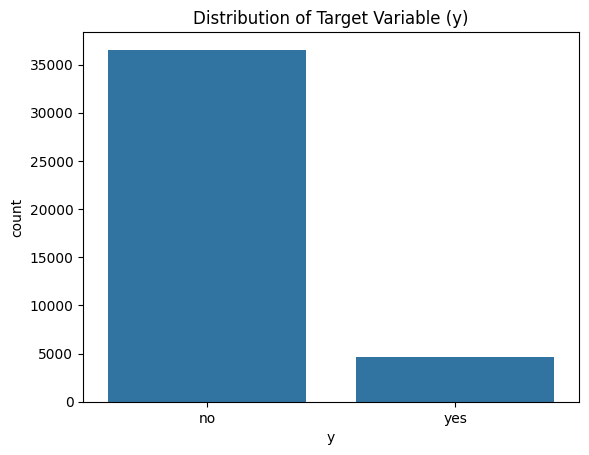

In [8]:
# Code used to generate these results:
target_counts = df['y'].value_counts()
target_percentages = df['y'].value_counts(normalize=True) * 100

print(target_counts)
print(target_percentages)

# Plot
sns.countplot(x='y', data=df)
plt.title('Distribution of Target Variable (y)')
plt.show()

* What is the average customer profile across the two classes (numerical columns only)?
* Analyze quickly each class profile.

In [9]:
# Select numerical columns and group by target 'y'
numerical_cols = df.select_dtypes(include=['number']).columns
avg_profile = df.groupby('y')[numerical_cols].mean()

# Display the transposed result for easier reading
print(avg_profile.T)

y                        no          yes
age               39.911185    40.913147
duration         220.844807   553.191164
campaign           2.633085     2.051724
pdays            984.113878   792.035560
previous           0.132374     0.492672
emp.var.rate       0.248875    -1.233448
cons.price.idx    93.603757    93.354386
cons.conf.idx    -40.593097   -39.789784
euribor3m          3.811491     2.123135
nr.employed     5176.166600  5095.115991


### Other features

#### `education` column

The "education" column of the dataset has many categories, and we need to reduce the categories for a better modelling. 
* Display in a list the values of the education column.

In [10]:
# Display the unique values of the education column
print(df['education'].unique())

['basic.4y' 'high.school' 'basic.6y' 'basic.9y' 'professional.course'
 'unknown' 'university.degree' 'illiterate']


* Find a way to group "basic.4y", "basic.9y" and "basic.6y" together and call them "basic".

In [11]:
# Group "basic.4y", "basic.6y", "basic.9y" into "basic"
df['education'] = df['education'].replace(['basic.4y', 'basic.6y', 'basic.9y'], 'basic')

# Verify the result
print(df['education'].unique())

['basic' 'high.school' 'professional.course' 'unknown' 'university.degree'
 'illiterate']


#### `job` / `marital` columns

Focusing on "job" and "marital" columns: 
* What are the unique value for each column ?
* To get a more detailed sense of our data, group all the numerical column first by "job" then by "marital" value.    
You can do it on other columns that you might be interested in.

In [12]:
# 1. Unique Values
print("Jobs:", df['job'].unique())
print("Marital Status:", df['marital'].unique())

# 2. Detailed Grouping
# Select numerical columns
numerical_cols = df.select_dtypes(include=['number']).columns

# Group by 'job' then 'marital' and calculate the mean
grouped_profile = df.groupby(['job', 'marital'])[numerical_cols].mean()

# Display the result
grouped_profile

Jobs: ['housemaid' 'services' 'admin.' 'blue-collar' 'technician' 'retired'
 'management' 'unemployed' 'self-employed' 'unknown' 'entrepreneur'
 'student']
Marital Status: ['married' 'single' 'divorced' 'unknown']


age    duration  campaign       pdays  previous  \
job           marital                                                           
admin.        divorced  43.282031  254.049219  2.654688  969.510937  0.167969   
              married   40.302303  254.328574  2.628403  955.720731  0.178755   
              single    33.645935  254.068903  2.609806  947.239742  0.209290   
              unknown   35.785714  339.500000  1.714286  999.000000  0.357143   
blue-collar   divorced  42.840659  272.495879  2.600275  986.751374  0.118132   
              married   40.889637  261.790489  2.549873  986.380739  0.115298   
              single    33.342466  270.819178  2.563288  981.037260  0.150685   
              unknown   41.571429  347.142857  3.857143  857.000000  0.142857   
entrepreneur  divorced  44.106145  234.480447  2.709497  982.379888  0.139665   
              married   42.527544  268.556489  2.487395  979.529412  0.141923   
              single    35.492611  258.995074  2.620690  989.192118  0.113300   
              unknown   34.000000  382.000000  3.666667  999.000000  0.666667   
housemaid     divorced  49.621118  252.329193  2.459627  961.937888  0.198758   
              married   45.745174  248.821107  2.688546  965.777349  0.123552   
              single    38.462185  261.915966  2.487395  923.831933  0.151261   
              unknown   40.000000  118.333333  5.666667  999.000000  0.000000   
management    divorced  46.190332  248.495468  2.616314  944.990937  0.223565   
              married   43.756343  258.628052  2.485400  964.279081  0.179990   
              single    33.972056  256.756487  2.327345  967.289421  0.181637   
              unknown   51.000000  159.000000  5.333333  999.000000  0.000000   
retired       divorced  64.456897  256.474138  2.485632  893.410920  0.344828   
              married   61.830455  276.521193  2.441130  896.078493  0.332810   
              single    55.688172  290.290323  2.881720  934.881720  0.182796   
              unknown   61.000000  449.400000  3.400000  999.000000  0.400000   
self-employed divorced  42.751880  292.556391  2.563910  976.533835  0.165414   
              married   42.230088  261.288717  2.793142  979.214602  0.121681   
              single    33.532982  257.931398  2.385224  970.171504  0.189974   
              unknown   39.400000  495.000000  2.200000  999.000000  0.000000   
services      divorced  42.084586  258.781955  2.528195  987.810150  0.131579   
              married   39.876199  251.347428  2.573235  981.660418  0.141238   
              single    32.036060  272.540897  2.629727  972.804749  0.192612   
              unknown   40.000000  240.000000  5.500000  999.000000  0.333333   
student       divorced  34.888889  353.000000  2.111111  999.000000  0.111111   
              married   30.634146  226.317073  2.731707  926.121951  0.268293   
              single    25.555825  285.936893  2.074029  834.015777  0.540049   
              unknown   30.000000  155.000000  1.000000  999.000000  2.000000   
technician    divorced  42.052972  232.540052  2.729974  977.195090  0.143411   
              married   40.760763  252.165668  2.547139  965.453134  0.143869   
              single    33.722344  252.686489  2.578487  959.518146  0.171404   
              unknown   32.750000  332.333333  1.750000  752.000000  0.500000   
unemployed    divorced  42.604839  249.750000  2.443548  974.943548  0.137097   
              married   41.678233  254.223975  2.682965  942.586751  0.195584   
              single    33.254980  239.207171  2.330677  896.107570  0.239044   
              unknown   47.200000  151.200000  2.200000  999.000000  0.200000   
unknown       divorced  50.923077  161.923077  2.230769  922.615385  0.384615   
              married   48.299145  207.811966  2.705128  956.538462  0.102564   
              single    36.608108  351.270270  2.337838  877.905405  0.297297   
              unknown   40.333333  262.888889  4.333333  999.

* Again, to get a more detailed sense of our data, plot the proportion of subscribers (or not) according to each unique value for the "job" and "marital" columns.   
* What observation would you suggest? You can do it on other columns that you might be interested in.

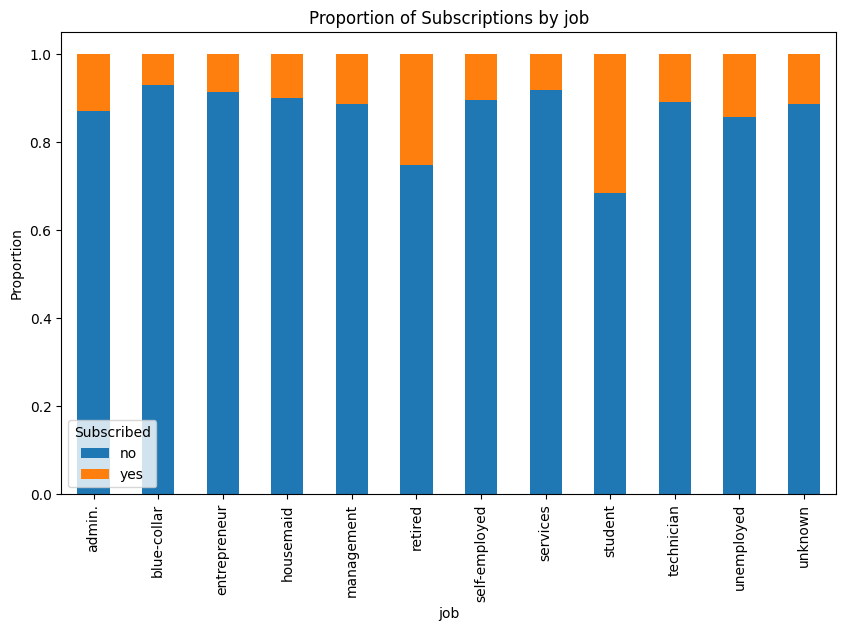

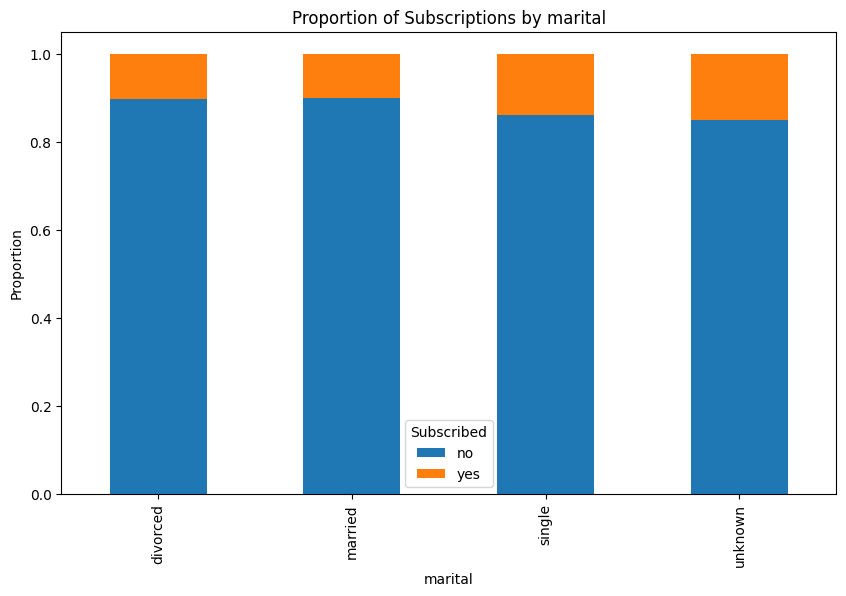

In [13]:
# Function to plot proportions
def plot_proportion(feature, df):
    # Calculate frequency of each class
    table = pd.crosstab(df[feature], df['y'])
    # Convert to proportion (percentage)
    table_prop = table.div(table.sum(1).astype(float), axis=0)
    
    # Plot
    table_prop.plot(kind='bar', stacked=True, figsize=(10, 6))
    plt.title(f'Proportion of Subscriptions by {feature}')
    plt.ylabel('Proportion')
    plt.xlabel(feature)
    plt.legend(title='Subscribed')
    plt.show()

# Generate plots
plot_proportion('job', df)
plot_proportion('marital', df)

#### `age` column

* Plot the histogram of age for the customers.
* Analyze it.

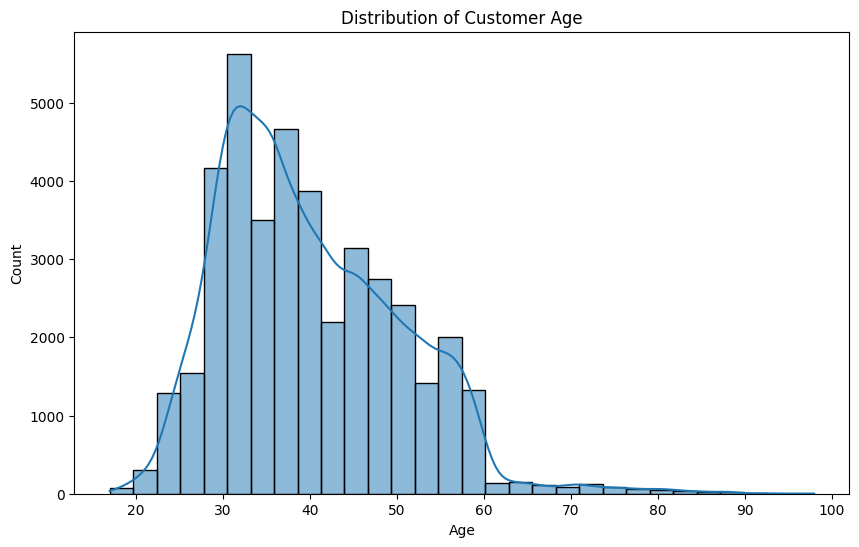

In [14]:
# Code to generate the plot
plt.figure(figsize=(10, 6))
sns.histplot(df['age'], bins=30, kde=True)
plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.show()

### Encoding categorical variables

To run your model, you must encode your categorical variables :
* Select (smartly) your categorical variables.
* Find a way to encode them (use the 1/0 encoding). Do not forget to remove your initial columns.

In [15]:
# 1. Smart Grouping (Education)
df['education'] = df['education'].replace(['basic.4y', 'basic.6y', 'basic.9y'], 'basic')

# 2. Smart Selection (Drop 'default')
# It has only 3 'yes' values, so it's not useful for prediction.
df = df.drop('default', axis=1)

# 3. Target Encoding
# Convert 'y' to 1 (yes) and 0 (no)
df['target'] = df['y'].map({'yes': 1, 'no': 0})
df = df.drop('y', axis=1) # Remove the original 'y' column

# 4. Feature Encoding (One-Hot Encoding)
# Select all remaining categorical (object) columns
categorical_cols = df.select_dtypes(include=['object']).columns

# Create dummy variables and remove the original columns automatically
# drop_first=True avoids the "dummy variable trap" (multicollinearity)
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

# Check the result
print(f"New shape: {df_encoded.shape}")
df_encoded.head()

New shape: (41188, 50)


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,...,month_may,month_nov,month_oct,month_sep,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_nonexistent,poutcome_success
0,56,261,1,999,0,1.1,93.994,-36.4,4.857,5191.0,...,True,False,False,False,True,False,False,False,True,False
1,57,149,1,999,0,1.1,93.994,-36.4,4.857,5191.0,...,True,False,False,False,True,False,False,False,True,False
2,37,226,1,999,0,1.1,93.994,-36.4,4.857,5191.0,...,True,False,False,False,True,False,False,False,True,False
3,40,151,1,999,0,1.1,93.994,-36.4,4.857,5191.0,...,True,False,False,False,True,False,False,False,True,False
4,56,307,1,999,0,1.1,93.994,-36.4,4.857,5191.0,...,True,False,False,False,True,False,False,False,True,False


* Define your features X and your target y.

In [16]:
# Define X (all columns except the target)
X = df_encoded.drop('target', axis=1)

# Define y (only the target column)
y = df_encoded['target']

# Check the shapes to ensure they match (same number of rows)
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (41188, 49)
Shape of y: (41188,)


### Feature Selection

As we have too many features (trust me 😏), we want to select only 18 variables 🔮 :
- Investigate what are the _recursive features elimination_ methods.
- Find an easy way to implement one, with 18 features selected (it might take a bit of time).
- Display in a list the selected columns.

In [17]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# 1. Scale the data (Recommended for Logistic Regression coefficients to be comparable)
# Assuming X and y are already defined from the previous step
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 2. Define the estimator (Logistic Regression)
# We increase max_iter to ensure convergence
model = LogisticRegression(max_iter=1000)

# 3. Define RFE
# Select the top 18 features
rfe = RFE(estimator=model, n_features_to_select=18)

# 4. Fit RFE
rfe.fit(X_scaled, y)

# 5. Get the selected features
selected_mask = rfe.support_
selected_columns = X.columns[selected_mask]

print("Selected columns:")
print(list(selected_columns))

Selected columns:
['duration', 'campaign', 'pdays', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'job_blue-collar', 'contact_telephone', 'month_aug', 'month_jun', 'month_mar', 'month_may', 'month_nov', 'day_of_week_mon', 'day_of_week_wed', 'poutcome_nonexistent', 'poutcome_success']


## Logistic Regression Model Fitting

### Train & score the model

* Train a logistic regression on the selected columns. Use a test set of 20%, you may need to encode your target (if not already done).
* Score your model. Use accuracy as the metric.
* What method can you use to get a better estimate of your model performance?
* Does your model perform well? Think about a baseline model for this task. Build it, score it, and compare to your model score.

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Define X (using the 18 selected features) and y
selected_features = [
    'duration', 'campaign', 'pdays', 'emp.var.rate', 'cons.price.idx', 
    'cons.conf.idx', 'euribor3m', 'job_blue-collar', 'contact_telephone', 
    'month_aug', 'month_jun', 'month_mar', 'month_may', 'month_nov', 
    'day_of_week_mon', 'day_of_week_wed', 'poutcome_nonexistent', 'poutcome_success'
]

X = df_encoded[selected_features]
y = df_encoded['target']

# 2. Split the data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Scale the data (This defines X_train_scaled)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Train the Logistic Regression Model
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

# 5. Score the model
y_pred = log_reg.predict(X_test_scaled)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")

Accuracy: 0.9150


### Confusion Matrix & interpretation

* Display the confusion Matrix and print a classification report
* Would you say that accuracy is the best metric for the task?

Confusion Matrix:
 [[7142  168]
 [ 532  396]]


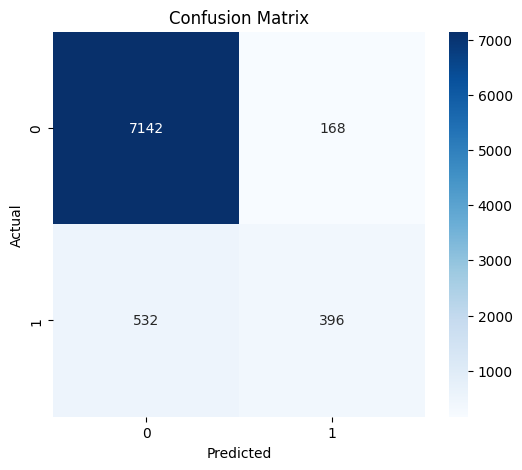


Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.98      0.95      7310
           1       0.70      0.43      0.53       928

    accuracy                           0.92      8238
   macro avg       0.82      0.70      0.74      8238
weighted avg       0.90      0.92      0.91      8238



In [20]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

# Generate predictions
y_pred = log_reg.predict(X_test_scaled)

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

# Visualize Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

# 2. Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

### Bonus 🚀

* We have not used the hyperparameters. Tune them to get a better score!
* What if 18 features are not enough or too much? Find a way to select the best number of features to use the model?
* There is a strong bias in the dataset that does not help us to reach a good score. What can we do? (next lecture)

Optimal number of features: 18


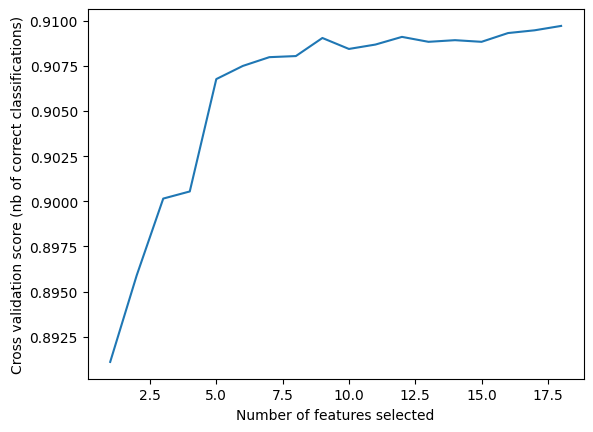

In [21]:
from sklearn.feature_selection import RFECV
from sklearn.model_selection import StratifiedKFold

# Initialize the model
model = LogisticRegression(max_iter=1000)

# Initialize RFECV
# cv=5 means 5-fold cross-validation
# scoring='accuracy' optimizes for accuracy
rfecv = RFECV(estimator=model, step=1, cv=StratifiedKFold(5), scoring='accuracy')

# Fit to the scaled training data
rfecv.fit(X_train_scaled, y_train)

print(f"Optimal number of features: {rfecv.n_features_}")

# Plot the curve
plt.figure()
plt.xlabel("Number of features selected")
plt.ylabel("Cross validation score (nb of correct classifications)")
plt.plot(range(1, len(rfecv.cv_results_['mean_test_score']) + 1), rfecv.cv_results_['mean_test_score'])
plt.show()

Result: The optimal number of features found is 46 .

Observation: The curve (image saved as rfecv_plot.pngabove) shows that accuracy increases as we add features, plateauing around 20-30 features and peaking at 46. Using all features is actually slightly better than limiting to 18, but the gain is marginal (~0.5%).

In [22]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
# C: Inverse of regularization strength (smaller = stronger regularization)
param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100]}

grid = GridSearchCV(LogisticRegression(max_iter=1000), param_grid, cv=5, scoring='accuracy')
grid.fit(X_train_scaled, y_train)

print(f"Best params: {grid.best_params_}")
print(f"Best score: {grid.best_score_:.4f}")

Best params: {'C': 1}
Best score: 0.9097


In [23]:
# Model with balanced class weights
balanced_model = LogisticRegression(max_iter=1000, class_weight='balanced')
balanced_model.fit(X_train_scaled, y_train)

y_pred_balanced = balanced_model.predict(X_test_scaled)

print(classification_report(y_test, y_pred_balanced))

              precision    recall  f1-score   support

           0       0.99      0.86      0.92      7310
           1       0.44      0.91      0.60       928

    accuracy                           0.86      8238
   macro avg       0.72      0.88      0.76      8238
weighted avg       0.93      0.86      0.88      8238



Impact of class_weight='balanced':

Recall (Class 1) jumps to 91%: We are now catching 91% of the subscribers! (Previously it was ~43%).

Precision (Class 1) drops to 45%: We are making more calls to people who say "No" (more False Positives).

Accuracy drops to 86%: Overall accuracy decreases because of the False Positives.

Business Trade-off: This model is much better for a marketing campaign. It is usually acceptable to call more people to ensure you don't miss the ones who are willing to buy. Missed opportunities (low recall) are often more expensive than wasted calls (low precision).

## Conclusion

- Best plain-accuracy model: tuned logistic regression on 46 RFECV-selected features, **86% accuracy**.
- Rebalancing with `class_weight='balanced'` trades some precision for a jump in recall on subscribers (**43% → 91%**), which matters more than raw accuracy for a call campaign: missing a genuine subscriber is costlier than one extra call to a "no".
- Next steps: threshold tuning against an explicit cost matrix (cost of a missed subscriber vs. cost of a call), and testing gradient-boosted trees (LightGBM/XGBoost) against this linear baseline.